# Employee Turnover Analytics — Portobello Tech

Predict which employees are likely to leave, understand why, and propose retention strategies.
Steps follow the project brief: data quality → EDA → clustering of leavers → SMOTE → 5-fold CV models → best model → retention zones.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, recall_score, precision_score, f1_score)
from imblearn.over_sampling import SMOTE

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

df = pd.read_csv("../HR_comma_sep.csv").rename(columns={"sales": "department"})
print(df.shape)
df.head()

(14999, 10)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


## 1. Data quality checks

In [2]:
df.info()
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Turnover rate (left = 1): {:.1%}".format(df["left"].mean()))

<class 'pandas.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   department             14999 non-null  str    
 9   salary                 14999 non-null  str    
dtypes: float64(2), int64(6), str(2)
memory usage: 1.1 MB

Missing values per column:
 satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left                     0
pr

**No missing values.** There are 3,008 fully duplicated rows; with no employee ID it is impossible to tell whether these are
genuine identical employees or double entries, so they are **kept** (as in the original source). The target is imbalanced: ~24% left.

## 2. EDA — what drives turnover?
### 2.1 Correlation heatmap

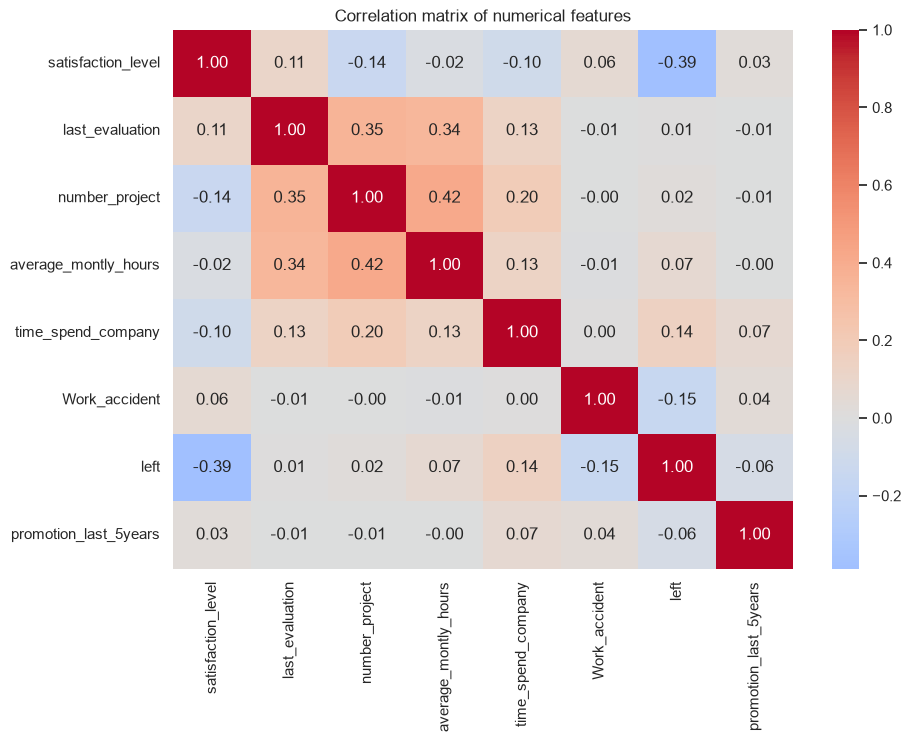

satisfaction_level      -0.388375
Work_accident           -0.154622
promotion_last_5years   -0.061788
last_evaluation          0.006567
number_project           0.023787
average_montly_hours     0.071287
time_spend_company       0.144822
Name: left, dtype: float64

In [3]:
num = df.select_dtypes("number")
plt.figure(figsize=(10, 7))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix of numerical features"); plt.show()
num.corr()["left"].drop("left").sort_values()

`satisfaction_level` has the strongest (negative) correlation with leaving; `time_spend_company`, `Work_accident` and
`average_montly_hours` follow. Projects, hours and evaluation are positively related to each other (busy, high-rated employees).

### 2.2 Distributions: satisfaction, evaluation, monthly hours

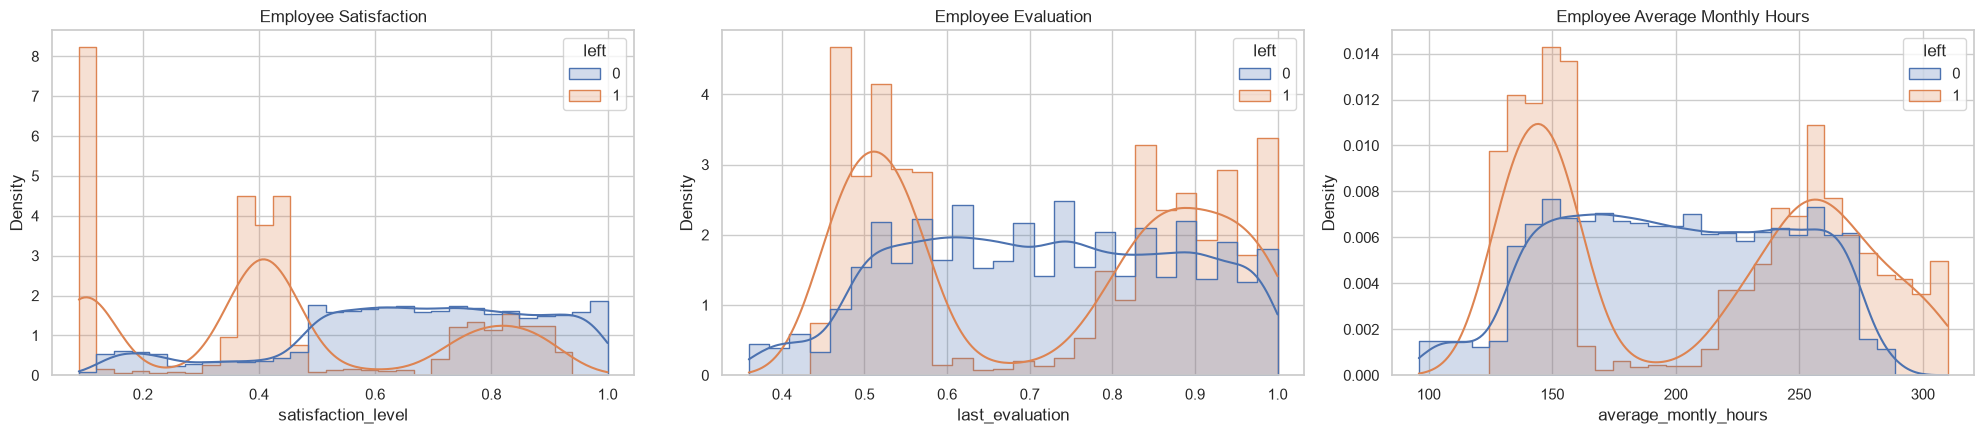

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
for ax, col, title in zip(axes, ["satisfaction_level", "last_evaluation", "average_montly_hours"],
                          ["Employee Satisfaction", "Employee Evaluation", "Employee Average Monthly Hours"]):
    sns.histplot(data=df, x=col, hue="left", kde=True, ax=ax, element="step", stat="density", common_norm=False)
    ax.set_title(title)
plt.tight_layout(); plt.show()

* **Satisfaction:** leavers cluster at very low (~0.1), mid-low (~0.4) and, surprisingly, high (~0.8) satisfaction.
* **Evaluation** and **monthly hours** are **bimodal for leavers**: one group is under-worked/low-rated (≈ 0.5 evaluation, ~150 h) and
  another is over-worked/high-rated (≈ 0.9 evaluation, ~250+ h). Stayers sit in between.

### 2.3 Project count of employees who left vs stayed

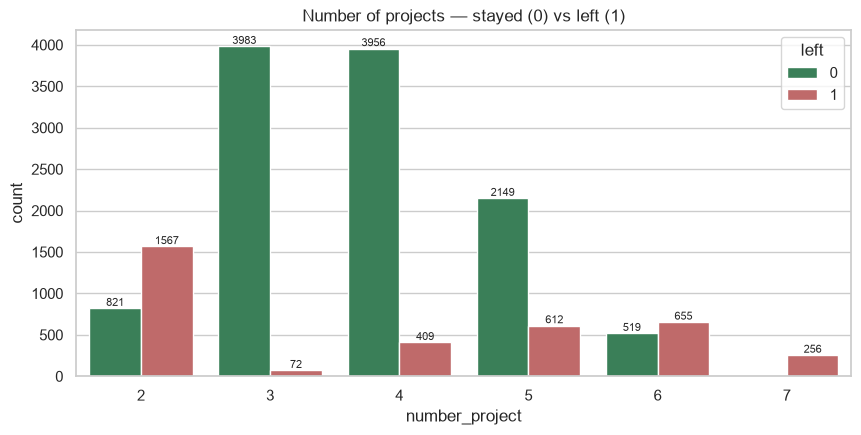

number_project,2,3,4,5,6,7
turnover_%,65.6,1.8,9.4,22.2,55.8,100.0


In [5]:
plt.figure(figsize=(10, 4.5))
ax = sns.countplot(data=df, x="number_project", hue="left", palette=["seagreen", "indianred"])
for c in ax.containers: ax.bar_label(c, fontsize=8)
plt.title("Number of projects — stayed (0) vs left (1)"); plt.show()
(df.groupby("number_project")["left"].mean() * 100).round(1).rename("turnover_%").to_frame().T

**Inference:** turnover is U-shaped in project load. Employees with **only 2 projects** leave at ~66% (under-utilised / disengaged) and
those with **6–7 projects** leave at 56–100% (burn-out). **3–4 projects** is the sweet spot with very low turnover.

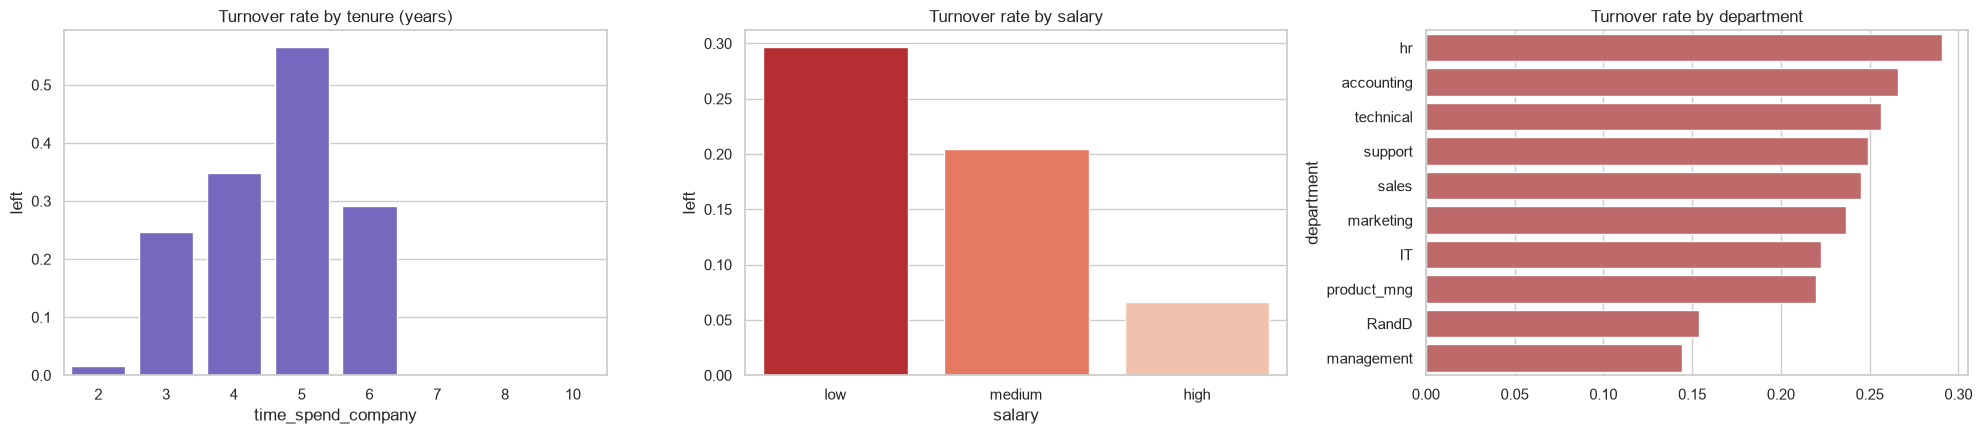

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
sns.barplot(data=df, x="time_spend_company", y="left", ax=axes[0], errorbar=None, color="slateblue"); axes[0].set_title("Turnover rate by tenure (years)")
sns.barplot(data=df, x="salary", y="left", order=["low", "medium", "high"], ax=axes[1], errorbar=None, palette="Reds_r"); axes[1].set_title("Turnover rate by salary")
dep = df.groupby("department")["left"].mean().sort_values(ascending=False)
sns.barplot(x=dep.values, y=dep.index, ax=axes[2], color="indianred"); axes[2].set_title("Turnover rate by department")
plt.tight_layout(); plt.show()

Turnover peaks at **5 years tenure** (and nobody with 7+ years leaves), is much higher for **low salary**, and almost absent among employees
who got a **promotion**. Departments differ little (HR and accounting slightly higher, management and R&D lower).

## 3. Clustering employees who left (satisfaction × evaluation)

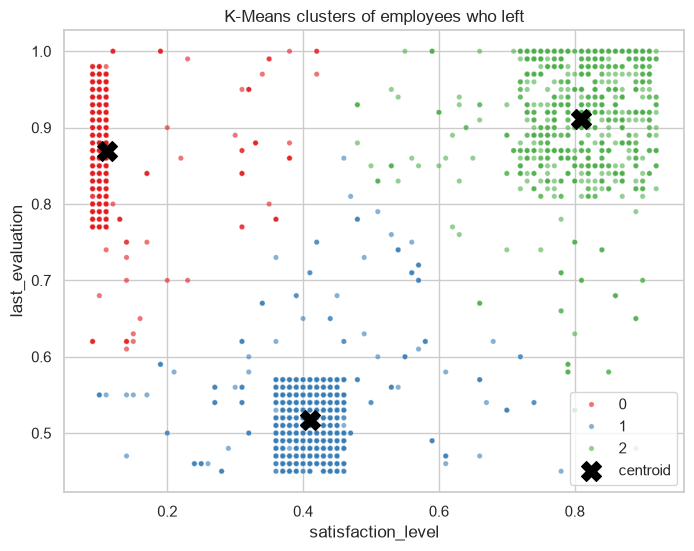

,satisfaction_level,last_evaluation,size
0,0.111,0.869,944
1,0.410,0.517,1650
2,0.809,0.912,977


In [7]:
left_df = df.loc[df["left"] == 1, ["satisfaction_level", "last_evaluation", "left"]].copy()
km = KMeans(n_clusters=3, n_init=20, random_state=123).fit(left_df[["satisfaction_level", "last_evaluation"]])
left_df["cluster"] = km.labels_
centers = pd.DataFrame(km.cluster_centers_, columns=["satisfaction_level", "last_evaluation"])
centers["size"] = left_df["cluster"].value_counts().sort_index()

plt.figure(figsize=(8, 6))
sns.scatterplot(data=left_df, x="satisfaction_level", y="last_evaluation", hue="cluster", palette="Set1", s=15, alpha=0.6)
plt.scatter(centers["satisfaction_level"], centers["last_evaluation"], c="black", s=200, marker="X", label="centroid")
plt.title("K-Means clusters of employees who left"); plt.legend(); plt.show()
centers.round(3)

In [8]:
def name_cluster(r):
    if r.satisfaction_level < 0.2: return "Overworked & frustrated (high eval, very low satisfaction)"
    if r.last_evaluation < 0.6: return "Under-performers (low eval, low-mid satisfaction)"
    return "High performers who left anyway (high eval, high satisfaction)"
centers["profile"] = centers.apply(name_cluster, axis=1)
centers.round(3)

,satisfaction_level,last_evaluation,size,profile
0,0.111,0.869,944,"Overworked & frustrated (high eval, very low s..."
1,0.410,0.517,1650,"Under-performers (low eval, low-mid satisfaction)"
2,0.809,0.912,977,"High performers who left anyway (high eval, hi..."


**Thoughts on the clusters**
1. **Overworked & frustrated** — excellent evaluations but satisfaction near 0.1. Linked to 6–7 projects and 250+ hours: classic burn-out.
   Retain through workload balancing and recognition.
2. **Under-performers / disengaged** — low evaluations and ~0.4 satisfaction, few projects and low hours. Likely a poor fit or were pushed out;
   some of this turnover may be acceptable, the rest needs coaching/re-engagement.
3. **Happy high performers** — high evaluation *and* satisfaction yet they left. These are probably poached for better pay/promotion
   (most have low/medium salary and no promotion). The most costly loss — target with career paths and compensation reviews.

## 4. Handling class imbalance with SMOTE
### 4.1 Pre-processing: categorical → numeric

In [9]:
cat_cols = ["department", "salary"]
num_cols = [c for c in df.columns if c not in cat_cols + ["left"]]
X_cat = pd.get_dummies(df[cat_cols], dtype=int)
X_num = df[num_cols]
X = pd.concat([X_num, X_cat], axis=1)
y = df["left"]
print("Feature matrix:", X.shape)
X.head()

Feature matrix: (14999, 20)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,department_IT,department_RandD,department_accounting,department_hr,department_management,department_marketing,department_product_mng,department_sales,department_support,department_technical,salary_high,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0
1,0.80,0.86,5,262,6,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1
2,0.11,0.88,7,272,4,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1
3,0.72,0.87,5,223,5,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0
4,0.37,0.52,2,159,3,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0


### 4.2 Stratified 80:20 split (random_state = 123)

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=123)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train class balance:\n", y_train.value_counts(normalize=True).round(3))

Train: (11999, 20) Test: (3000, 20)
Train class balance:
 left
0    0.762
1    0.238
Name: proportion, dtype: float64


### 4.3 Upsample the training set with SMOTE

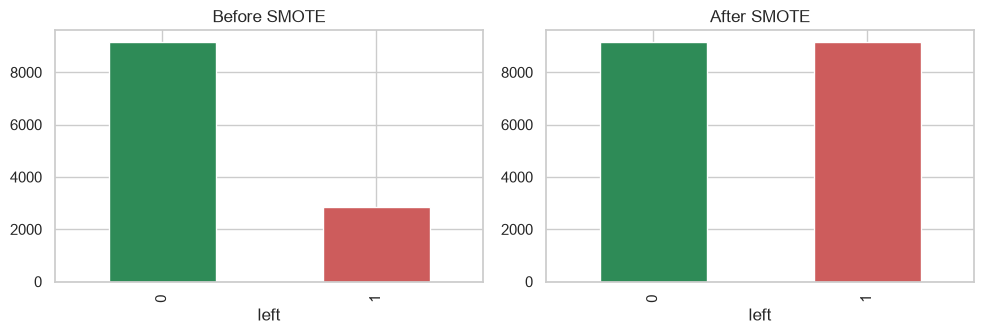

After SMOTE: {0: 9142, 1: 9142}


In [11]:
sm = SMOTE(random_state=123)
X_train_sm, y_train_sm = sm.fit_resample(X_train, y_train)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
y_train.value_counts().plot.bar(ax=axes[0], color=["seagreen", "indianred"], title="Before SMOTE")
y_train_sm.value_counts().plot.bar(ax=axes[1], color=["seagreen", "indianred"], title="After SMOTE")
plt.tight_layout(); plt.show()
print("After SMOTE:", y_train_sm.value_counts().to_dict())

## 5. 5-fold cross-validation training
Each model is trained with stratified 5-fold CV on the SMOTE-balanced training data. The CV predictions give a classification report
per model (5.1-5.3).

===== Logistic Regression (5-fold CV) =====
              precision    recall  f1-score   support

           0      0.811     0.799     0.805      9142
           1      0.802     0.814     0.808      9142

    accuracy                          0.807     18284
   macro avg      0.807     0.807     0.807     18284
weighted avg      0.807     0.807     0.807     18284



===== Random Forest (5-fold CV) =====
              precision    recall  f1-score   support

           0      0.975     0.993     0.984      9142
           1      0.993     0.975     0.984      9142

    accuracy                          0.984     18284
   macro avg      0.984     0.984     0.984     18284
weighted avg      0.984     0.984     0.984     18284



===== Gradient Boosting (5-fold CV) =====
              precision    recall  f1-score   support

           0      0.945     0.976     0.961      9142
           1      0.976     0.943     0.959      9142

    accuracy                          0.960     18284
   macro avg      0.960     0.960     0.960     18284
weighted avg      0.960     0.960     0.960     18284



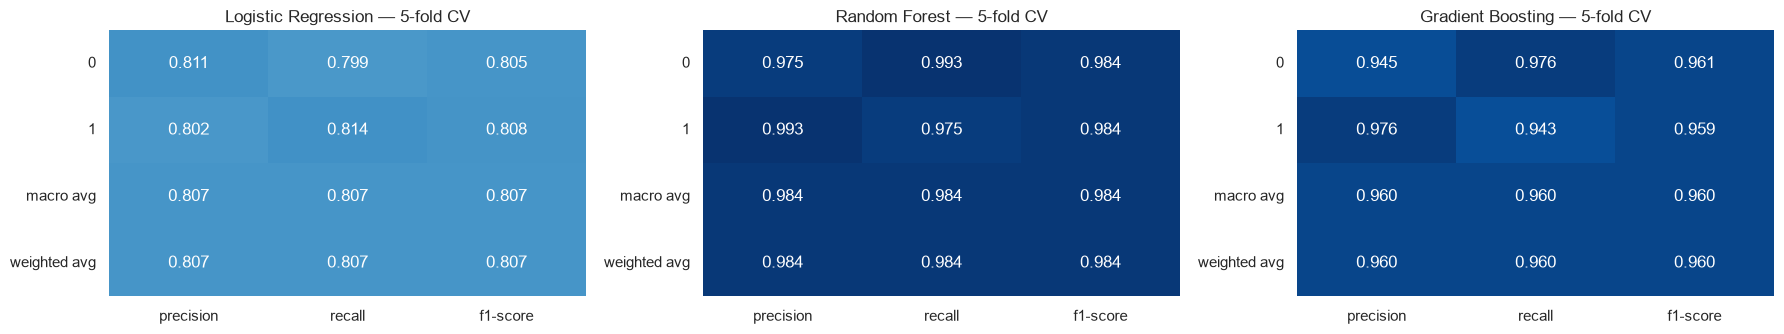

,accuracy,recall,precision,f1,roc_auc
Logistic Regression,0.8066,0.8140,0.8021,0.8080,0.8821
Random Forest,0.9841,0.9748,0.9933,0.9840,0.9977
Gradient Boosting,0.9599,0.9433,0.9756,0.9592,0.9921


In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=123, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=123),
}

def plot_report(report_dict, title, ax):
    rep = pd.DataFrame(report_dict).T.loc[["0", "1", "macro avg", "weighted avg"], ["precision", "recall", "f1-score"]]
    sns.heatmap(rep, annot=True, fmt=".3f", cmap="Blues", vmin=0.5, vmax=1, ax=ax, cbar=False)
    ax.set_title(title)

cv_scores = {}
fig, axes = plt.subplots(1, 3, figsize=(18, 3.5))
for ax, (name, model) in zip(axes, models.items()):
    y_cv = cross_val_predict(model, X_train_sm, y_train_sm, cv=cv, n_jobs=-1)
    print(f"===== {name} (5-fold CV) =====")
    print(classification_report(y_train_sm, y_cv, digits=3))
    plot_report(classification_report(y_train_sm, y_cv, output_dict=True), f"{name} — 5-fold CV", ax)
    s = cross_validate(model, X_train_sm, y_train_sm, cv=cv, scoring=["accuracy", "recall", "precision", "f1", "roc_auc"], n_jobs=-1)
    cv_scores[name] = {k.replace("test_", ""): v.mean() for k, v in s.items() if k.startswith("test_")}
plt.tight_layout(); plt.show()
pd.DataFrame(cv_scores).T.round(4)

## 6. Best model & evaluation metrics
Models are refit on the full SMOTE training set and evaluated on the untouched (imbalanced) **test set**.
### 6.1 ROC / AUC

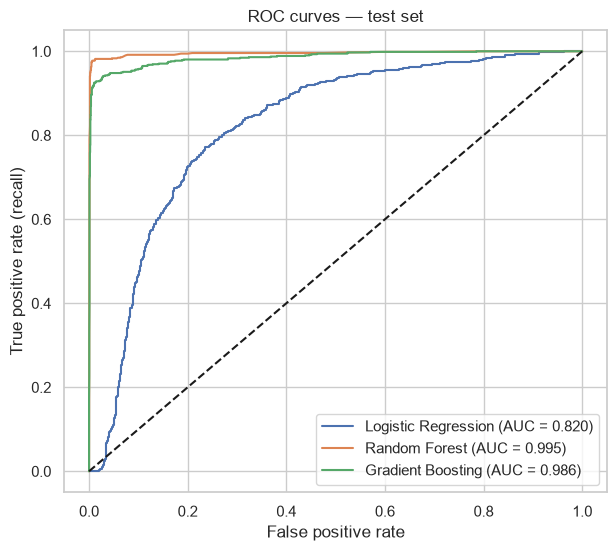

,AUC,Recall,Precision,F1,Accuracy
Random Forest,0.9952,0.9776,0.9721,0.9749,0.9880
Gradient Boosting,0.9857,0.9342,0.9200,0.9270,0.9650
Logistic Regression,0.8202,0.7087,0.5304,0.6067,0.7813


In [13]:
fitted, results = {}, {}
plt.figure(figsize=(7, 6))
for name, model in models.items():
    model.fit(X_train_sm, y_train_sm); fitted[name] = model
    proba = model.predict_proba(X_test)[:, 1]; pred = (proba >= 0.5).astype(int)
    auc = roc_auc_score(y_test, proba)
    results[name] = {"AUC": auc, "Recall": recall_score(y_test, pred), "Precision": precision_score(y_test, pred),
                     "F1": f1_score(y_test, pred), "Accuracy": (pred == y_test).mean()}
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall)")
plt.title("ROC curves — test set"); plt.legend(); plt.show()
res = pd.DataFrame(results).T.sort_values("AUC", ascending=False).round(4)
res

### 6.2 Confusion matrices

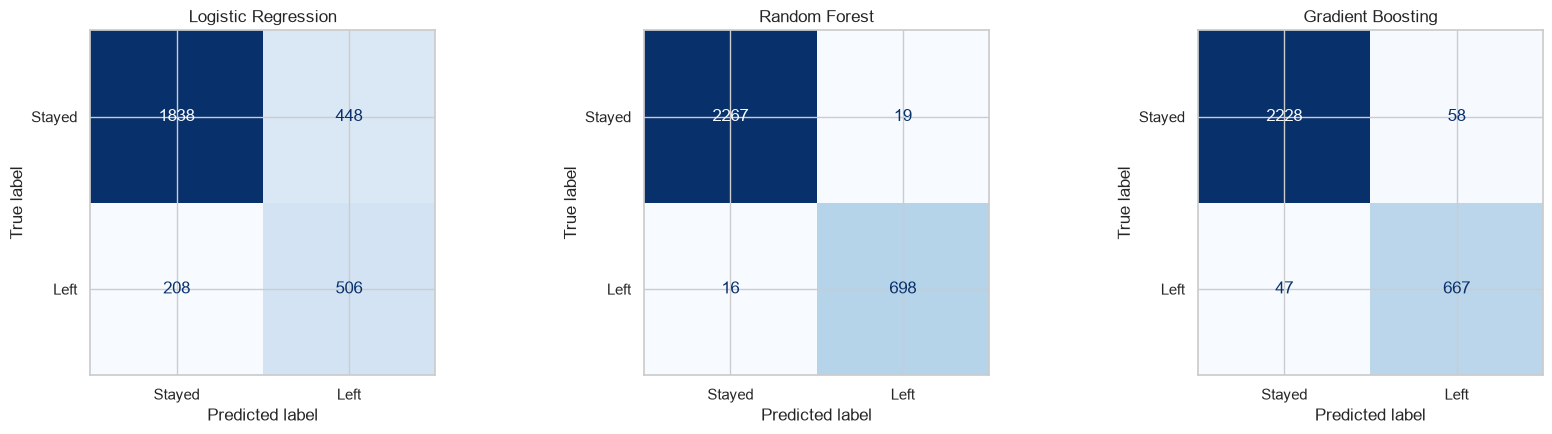

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (name, model) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, model.predict(X_test)), display_labels=["Stayed", "Left"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

> **Caveat:** because the 3,008 duplicated rows were kept, some identical records fall into both train and test, which makes test scores
> optimistic for the tree models. As a robustness check, re-running the same pipeline on de-duplicated data gives
> Gradient Boosting AUC 0.978 / recall 0.92, Random Forest AUC 0.976 / recall 0.90 and Logistic Regression AUC 0.81 / recall 0.57.
> The two ensembles are then essentially tied (Gradient Boosting marginally ahead); both clearly beat logistic regression.

### 6.3 Recall or precision?
**Recall** (of the "left" class) is the metric to prioritise. A **false negative** — predicting an employee will stay when they actually
leave — is far more expensive (lost talent, hiring and training costs, lost productivity) than a **false positive**, which only costs a
retention conversation or a small incentive. We therefore pick the model with the best recall while keeping precision and AUC high.

Best model: Random Forest
AUC          0.9952
Recall       0.9776
Precision    0.9721
F1           0.9749
Accuracy     0.9880
Name: Random Forest, dtype: float64


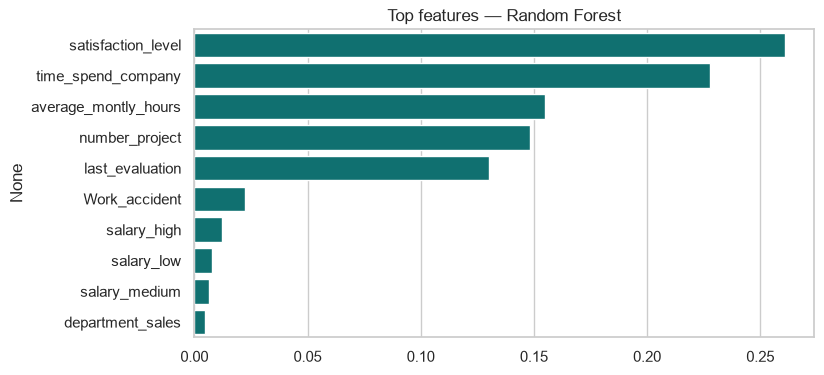

In [15]:
best_name = res.sort_values(["Recall", "AUC"], ascending=False).index[0]
best_model = fitted[best_name]
print(f"Best model: {best_name}")
print(res.loc[best_name])
if hasattr(best_model, "feature_importances_"):
    imp = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
    plt.figure(figsize=(8, 4)); sns.barplot(x=imp.values, y=imp.index, color="teal"); plt.title(f"Top features — {best_name}"); plt.show()

## 7. Retention strategies
### 7.1 Turnover probability on the test set with the best model
### 7.2 Risk zones

,employees,avg_prob,actually_left_pct,avg_satisfaction,avg_hours,avg_projects,avg_tenure
zone,,,,,,,
Safe Zone (Green),2161,0.03,0.51,0.68,198.23,3.76,3.34
Low-Risk Zone (Yellow),131,0.32,5.34,0.45,217.56,3.93,3.95
Medium-Risk Zone (Orange),58,0.76,86.21,0.57,224.62,4.53,4.29
High-Risk Zone (Red),650,0.99,99.38,0.43,208.71,3.85,3.88


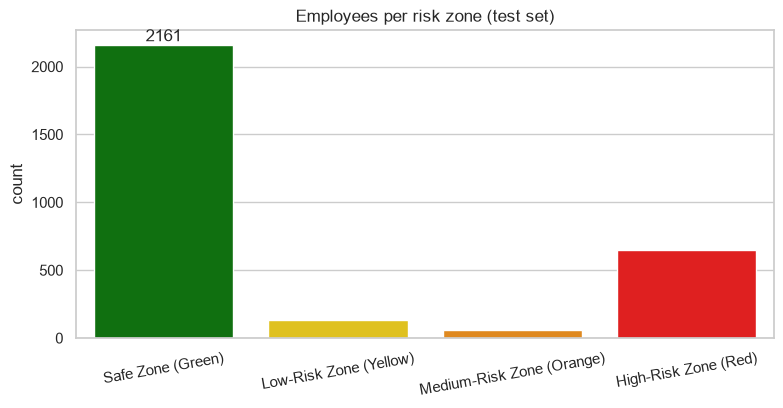

In [16]:
test = X_test.copy()
test["left_actual"] = y_test
test["turnover_prob"] = best_model.predict_proba(X_test)[:, 1]
bins = [-0.001, 0.20, 0.60, 0.90, 1.0]
labels = ["Safe Zone (Green)", "Low-Risk Zone (Yellow)", "Medium-Risk Zone (Orange)", "High-Risk Zone (Red)"]
test["zone"] = pd.cut(test["turnover_prob"], bins=bins, labels=labels)
zone_summary = test.groupby("zone", observed=False).agg(
    employees=("turnover_prob", "size"), avg_prob=("turnover_prob", "mean"), actually_left_pct=("left_actual", "mean"),
    avg_satisfaction=("satisfaction_level", "mean"), avg_hours=("average_montly_hours", "mean"),
    avg_projects=("number_project", "mean"), avg_tenure=("time_spend_company", "mean"))
zone_summary["actually_left_pct"] *= 100
display(zone_summary.round(2))

plt.figure(figsize=(9, 4))
ax = sns.countplot(x=test["zone"], palette=["green", "gold", "darkorange", "red"], order=labels)
ax.bar_label(ax.containers[0]); plt.xticks(rotation=10); plt.title("Employees per risk zone (test set)"); plt.xlabel(""); plt.show()

**Retention strategy per zone**

| Zone | Score | Strategy |
|---|---|---|
| 🟢 **Safe** | < 20% | Maintain engagement: regular check-ins, recognition, career conversations; use as mentors. No special spend. |
| 🟡 **Low-Risk** | 20–60% | Monitor: pulse surveys on satisfaction, balance project load to the 3–4 project sweet spot, learning opportunities. |
| 🟠 **Medium-Risk** | 60–90% | Act proactively: 1-on-1 with manager, workload review (cap hours/projects), clear promotion path, salary benchmarking. |
| 🔴 **High-Risk** | > 90% | Immediate intervention: retention interview, compensation/promotion review for high performers, reduce overtime for burnt-out staff, flexible work; plan knowledge transfer/succession in case they leave. |

Across all zones, the EDA points to the same levers: **manage workload** (avoid both 2 and 6+ projects), **reward high performers with
promotion and pay** (low salary and no promotion drive exits), and **watch the 4–5 year tenure mark**.